[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MuhammadErlanggaKurniawan/ets-ml2-kelompok/blob/main/notebooks/eksperimen_michael_ensemble.ipynb)

# Eksperimen Ensemble Tambahan
**Dikerjakan oleh:** Michael Valencio Erasmo Bagas Ganendra · lanjutan dari notebook utama `ETS_ML2_Kesegaran_Ayam.ipynb` (slide 5–7)

Notebook ini menguji **ensemble learning** lebih jauh. Data dan fiturnya sama persis dengan notebook utama, jadi angka
awalnya harus sama dengan slide.

## Cara mengerjakan
1. Jalankan sel dari atas ke bawah (**Shift + Enter**), atau pilih Runtime → Run all.
2. Di sel bertanda **✏️ UBAH DI SINI**, coba ganti angkanya, jalankan lagi, dan perhatikan hasilnya.
3. Di sel bertanda **✍️ TULIS DI SINI**, tulis pengamatanmu dengan kata-katamu sendiri (klik dua kali sel
   itu untuk mengedit).
4. Setiap selesai satu langkah, simpan ke GitHub: **File → Save a copy in GitHub**. Pilih repo
   `MuhammadErlanggaKurniawan/ets-ml2-kelompok`, branch `main`, path `notebooks/eksperimen_michael_ensemble.ipynb`, lalu tulis pesan commit singkat (contoh di tiap langkah).
   Satu kali simpan = satu commit atas nama akunmu.

---
## Langkah 0 — Siapkan data (sama dengan notebook utama)
Sel ini mengunduh data, membuat label, merangkum per 5 menit, dan membuat 19 fitur. Cukup dijalankan, tidak perlu
diubah. Butuh sekitar 30 detik.

In [1]:
import hashlib, urllib.request, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import LeaveOneGroupOut

warnings.filterwarnings("ignore")
SEED = 42
CLASSES = ["Fresh", "Semi-fresh", "Spoiled"]
URL = ("https://raw.githubusercontent.com/talhaanwarch/chicken_assessment_e-nose/"
       "e7e3ca686bce0ef3e5c59f9833c85a3190c36e6e/complete_data.csv")
SHA256 = "7c9920fcfe523af1ee2855d53f13334ddba93db5135d7868b9f63c5cd488d953"
path = Path("data/raw/complete_data.csv")
if not path.exists():
    path.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(URL, path)
assert hashlib.sha256(path.read_bytes()).hexdigest() == SHA256, "Isi file berbeda dari sumber asli"

SENSOR_NAMES = {"s1": "MQ-135", "s2": "MQ-2", "s3": "MQ-3", "s4": "MQ-6", "s5": "MQ-7", "s6": "MQ-9",
                "s8": "Kelembapan"}
raw = pd.read_csv(path).rename(columns={**SENSOR_NAMES, "hour": "jam", "group": "sesi"})
MQ = ["MQ-135", "MQ-2", "MQ-3", "MQ-6", "MQ-7", "MQ-9"]
SENSORS = MQ + ["Kelembapan"]
long_session = raw.groupby("sesi")["jam"].transform("max") > 15
raw["label"] = np.select([raw.jam <= np.where(long_session, 8, 5), raw.jam <= np.where(long_session, 16, 10)],
                         [0, 1], 2)


def make_windows(readings):
    r = readings.copy()
    r["urutan"] = r.groupby(["sesi", "jam"]).cumcount()
    r["n"] = r.groupby(["sesi", "jam"])["jam"].transform("size")
    r["jendela"] = r.urutan * 12 // r.n
    return r.groupby(["sesi", "jam", "jendela"]).agg(**{c: (c, "mean") for c in SENSORS},
                                                    label=("label", "first")).reset_index()


def make_features(win):
    level = np.log1p(win[MQ].clip(lower=0))
    reference = level.where(win.jam == 1).groupby(win.sesi).transform("mean")
    keep = (win.jam >= 2).to_numpy()
    rows = win[keep].reset_index(drop=True)
    level, reference = level[keep].reset_index(drop=True), reference[keep].reset_index(drop=True)
    gas = rows[MQ].clip(lower=0)
    features = pd.concat([level.add_prefix("level_"), gas.div(gas.sum(axis=1) + 1, axis=0).add_prefix("porsi_"),
                          (level - reference).add_prefix("naik_"), rows[["Kelembapan"]]], axis=1)
    return features, rows


features, data = make_features(make_windows(raw))
X, y, groups = features.to_numpy(), data.label.to_numpy(), data.sesi.to_numpy()


def loso(make_model, X_=None):
    # every window is predicted by a model that never saw its session
    X_ = X if X_ is None else X_
    pred, proba = np.empty_like(y), np.zeros((len(y), 3))
    for train, test in LeaveOneGroupOut().split(X_, y, groups):
        model = make_model().fit(X_[train], y[train])
        pred[test], proba[test] = model.predict(X_[test]), model.predict_proba(X_[test])
    return pred, proba


def score(pred):
    return {"akurasi": round(accuracy_score(y, pred), 3), "macro_f1": round(f1_score(y, pred, average="macro"), 3)}


make_rf = lambda: RandomForestClassifier(n_estimators=300, max_depth=6, random_state=SEED, n_jobs=-1)
print(f"Data siap: {len(data)} jendela, {X.shape[1]} fitur, {len(np.unique(groups))} sesi.")

Data siap: 3468 jendela, 19 fitur, 15 sesi.


---
## Langkah 1 — Ulangi hasil Random Forest di slide
Hasilnya harus **akurasi 0,776 dan macro-F1 0,782** (slide 6). Kalau beda sedikit di Colab, itu karena versi
library; catat saja.

💾 Pesan commit contoh: `ulangi baseline Random Forest`

In [2]:
pred_rf, _ = loso(make_rf)
hasil = {"Random Forest (300 pohon)": score(pred_rf)}
print(hasil)

{'Random Forest (300 pohon)': {'akurasi': 0.776, 'macro_f1': 0.782}}


Hasil evaluasi Random Forest menunjukkan angka yang sama dengan sebelumnya dengan akurasinya 0.776 dan macro-F1 0.782

---
## Langkah 2 — Extra Trees (ensemble bagging yang lebih acak)
Extra Trees mirip Random Forest, tapi titik potong di tiap pohon dipilih **acak**. Kadang ini membuat model lebih
tahan terhadap perbedaan antar sesi.

💾 Pesan commit contoh: `coba Extra Trees`

In [19]:
from sklearn.ensemble import ExtraTreesClassifier

N_POHON = 800      # ✏️ UBAH DI SINI (coba 100 atau 500)
KEDALAMAN = 7      # ✏️ UBAH DI SINI (coba 4 atau 10)

pred_et, _ = loso(lambda: ExtraTreesClassifier(n_estimators=N_POHON, max_depth=KEDALAMAN, random_state=SEED, n_jobs=-1))
hasil[f"Extra Trees ({N_POHON} pohon, kedalaman {KEDALAMAN})"] = score(pred_et)
display(pd.DataFrame(hasil).T)

,akurasi,macro_f1
Random Forest (300 pohon),0.776,0.782
"Extra Trees (300 pohon, kedalaman 6)",0.780,0.785
"Extra Trees (500 pohon, kedalaman 6)",0.781,0.787
"Extra Trees (500 pohon, kedalaman 10)",0.780,0.786
"Extra Trees (500 pohon, kedalaman 4)",0.769,0.776
"Extra Trees (100 pohon, kedalaman 4)",0.763,0.769
"Extra Trees (100 pohon, kedalaman 10)",0.773,0.779
"Extra Trees (300 pohon, kedalaman 10)",0.780,0.786
"LightGBM (200 pohon, lr 0.05)",0.765,0.770
"LightGBM (200 pohon, lr 0.01)",0.742,0.747


Hasil dari extra trees sedikit lebih baik daripada random forest, dengan perbedaan hasil akurasi 0.781 dan 0.776. Karena extra trees membagi datanya secara acak sehingga tidak mudah terjadi overfitting.

---
## Langkah 3 — LightGBM (ensemble boosting lain)
LightGBM mirip XGBoost: pohon dibuat berurutan, tiap pohon memperbaiki kesalahan sebelumnya, tapi cara
menumbuhkan pohonnya berbeda (per daun, bukan per tingkat).

💾 Pesan commit contoh: `coba LightGBM`

In [18]:
from lightgbm import LGBMClassifier

N_POHON_LGBM = 400     # ✏️ UBAH DI SINI
LEARNING_RATE = 0.05   # ✏️ UBAH DI SINI (coba 0.01 atau 0.1)

pred_lgbm, _ = loso(lambda: LGBMClassifier(n_estimators=N_POHON_LGBM, num_leaves=15, learning_rate=LEARNING_RATE,
                                           random_state=SEED, verbose=-1))
hasil[f"LightGBM ({N_POHON_LGBM} pohon, lr {LEARNING_RATE})"] = score(pred_lgbm)
display(pd.DataFrame(hasil).T)

,akurasi,macro_f1
Random Forest (300 pohon),0.776,0.782
"Extra Trees (300 pohon, kedalaman 6)",0.780,0.785
"Extra Trees (500 pohon, kedalaman 6)",0.781,0.787
"Extra Trees (500 pohon, kedalaman 10)",0.780,0.786
"Extra Trees (500 pohon, kedalaman 4)",0.769,0.776
"Extra Trees (100 pohon, kedalaman 4)",0.763,0.769
"Extra Trees (100 pohon, kedalaman 10)",0.773,0.779
"Extra Trees (300 pohon, kedalaman 10)",0.780,0.786
"LightGBM (200 pohon, lr 0.05)",0.765,0.770
"LightGBM (200 pohon, lr 0.01)",0.742,0.747


Menurut hasil yang didapat LightGBM sedikit lebih baik hasilnya dibandingkan dengan XGBoost, dengan perbandingan 0.770 dan 0.765.

---
## Langkah 4 — Apakah lebih banyak pohon selalu lebih baik?
Random Forest dicoba dengan jumlah pohon berbeda.

💾 Pesan commit contoh: `uji jumlah pohon Random Forest`

  10 pohon → macro-F1 0.73
  50 pohon → macro-F1 0.762
 100 pohon → macro-F1 0.773
 300 pohon → macro-F1 0.782
 500 pohon → macro-F1 0.781


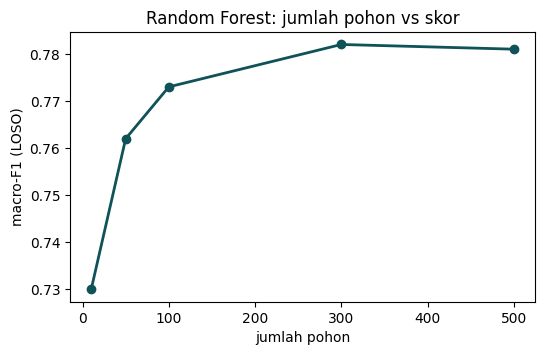

In [15]:
JUMLAH_POHON = [10, 50, 100, 300, 500]   # ✏️ UBAH DI SINI (boleh tambah, misalnya 500)

f1_per_pohon = {}
for n in JUMLAH_POHON:
    pred, _ = loso(lambda: RandomForestClassifier(n_estimators=n, max_depth=6, random_state=SEED, n_jobs=-1))
    f1_per_pohon[n] = score(pred)["macro_f1"]
    print(f"{n:>4} pohon → macro-F1 {f1_per_pohon[n]}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(list(f1_per_pohon), list(f1_per_pohon.values()), marker="o", color="#0F5257", lw=2)
ax.set(xlabel="jumlah pohon", ylabel="macro-F1 (LOSO)", title="Random Forest: jumlah pohon vs skor")
plt.show()

Hasil yang didapat menunjukkan semakin banyak pohon tidak selalu lebih baik. Performa naik terus dari 10 hingga 300 pohon (0.782), tapi di 500 pohon malah sedikit turun (0.781). Sehingga dari hasil yang didapat 300 pohon adalah titik optimalnya.

---
## Langkah 5 — Model mana yang paling stabil antar sesi?
Akurasi dihitung per sesi untuk tiap model. Model yang bagus bukan cuma rata-ratanya tinggi, tapi juga tidak
terlalu jelek di sesi tertentu.

💾 Pesan commit contoh: `bandingkan akurasi per sesi`

,Random Forest,Extra Trees,LightGBM
sesi,,,
0,0.846,0.933,0.526
1,0.598,0.634,0.862
2,0.600,0.450,0.627
3,0.793,0.830,0.764
4,0.819,0.804,0.779
5,0.931,0.938,0.880
6,0.826,0.792,0.830
7,0.707,0.725,0.750
8,0.762,0.726,0.782


Akurasi terendah tiap model:
Random Forest    0.553
Extra Trees      0.450
LightGBM         0.523
dtype: float64


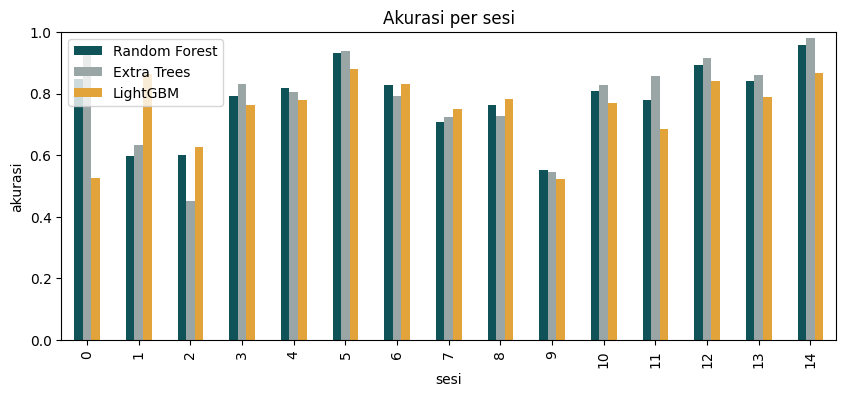

In [16]:
per_sesi = pd.DataFrame({
    nama: [accuracy_score(y[groups == s], pred[groups == s]) for s in np.unique(groups)]
    for nama, pred in [("Random Forest", pred_rf), ("Extra Trees", pred_et), ("LightGBM", pred_lgbm)]
}, index=np.unique(groups))
per_sesi.index.name = "sesi"
display(per_sesi.round(3))
print("Akurasi terendah tiap model:")
print(per_sesi.min().round(3))

per_sesi.plot.bar(figsize=(10, 4), color=["#0F5257", "#9AA5A6", "#E3A33B"])
plt.ylabel("akurasi")
plt.title("Akurasi per sesi")
plt.ylim(0, 1)
plt.show()

Sesi paling sulit untuk semua model adalah Sesi 9. Di sesi ini, Random Forest (0.553) dan LightGBM (0.523) mendapatkan nilai terendahnya, dan Extra Trees juga ikut turun di angka 0.545.
Dari hasil yang didapat model yang paling stabil adalah LightGBM.Karena rentang nilainya paling sempit (dari 0.523 sampai 0.880), jadi naik turun nilainya tidak terlalu ekstrem. Sebaliknya, Extra Trees paling tidak stabil karena naik-turun nilainya paling besar.

---
## Langkah 6 — Kesimpulan
💾 Pesan commit contoh: `tulis kesimpulan eksperimen ensemble`

In [17]:
display(pd.DataFrame(hasil).T.sort_values("macro_f1", ascending=False))

,akurasi,macro_f1
"Extra Trees (500 pohon, kedalaman 6)",0.781,0.787
"Extra Trees (500 pohon, kedalaman 10)",0.780,0.786
"Extra Trees (300 pohon, kedalaman 10)",0.780,0.786
"Extra Trees (300 pohon, kedalaman 6)",0.780,0.785
Random Forest (300 pohon),0.776,0.782
"Extra Trees (100 pohon, kedalaman 10)",0.773,0.779
"Extra Trees (500 pohon, kedalaman 4)",0.769,0.776
"LightGBM (200 pohon, lr 0.05)",0.765,0.770
"Extra Trees (100 pohon, kedalaman 4)",0.763,0.769
"LightGBM (200 pohon, lr 0.1)",0.751,0.756


Model ensemble yang terbaik dari hasil yang didapat adalah model Ekstra Trees dengan 500 pohon dan 6 kedalaman, hasil dari model ini sedikit lebih unggul dari model random forest, sehinga model ekstra trees menjadi lebih unggul. Sehingga dapat disimpulkan bahwa model ensemble secara konsisten mengalahkan model tunggal, dan sifat Extra Trees yang lebih acak dalam membagi data membuatnya lebih optimal serta tahan overfitting dibanding Random Forest pada dataset ini